# Implied Volatility and Numerical Root Finding

## Objective

This notebook investigates the numerical estimation of
implied volatility from European option prices.

The analysis includes:
- Recovering implied volatility from Black-Scholes prices.
- Implementing Brent's root-finding method.
- Implementing Newton-Raphson using analytical Vega.
- Comparing numerical accuracy and convergence.
- Investigating volatility smiles across strike prices.

## Model Assumptions

European options, no dividends, constant risk-free rate,
and the Black-Scholes pricing framework.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate project root
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

assert (project_root / "src").is_dir(), "Project root not found"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.black_scholes import black_scholes
from src.greeks import analytical_vega

# Import implied volatility solvers
from src import implied_volatility as iv

# Aliases for notebook compatibility
implied_volatility_brent = iv.implied_volatility_brent
implied_volatility_newton = iv.implied_volatility_newton

# Create figures directory
figures_path = project_root / "figures"
figures_path.mkdir(parents=True, exist_ok=True)

print(f"Figures directory: {figures_path}")

# Model parameters
S = 100
K = 100
T = 1
r = 0.05

# Volatility used to generate a benchmark price
sigma_true = 0.20

market_price = black_scholes(S, K, T, r, sigma_true, "call")

print(f"Target Option Price: {market_price:.6f}")

Figures directory: /Users/macbook/quant-option-pricing/figures
Target Option Price: 10.450584


In [2]:
def pricing_error(sigma):
    """
    Difference between Black-Scholes price
    and the target option price.
    """
    model_price = black_scholes(
        S, K, T, r, sigma, "call"
    )

    return model_price - market_price


# Evaluate the function at different volatilities
for sigma in [0.10, 0.20, 0.40]:

    error = pricing_error(sigma)

    print(
        f"Volatility: {sigma:.0%} | "
        f"Pricing Error: {error:.6f}")

Volatility: 10% | Pricing Error: -3.645626
Volatility: 20% | Pricing Error: 0.000000
Volatility: 40% | Pricing Error: 7.572368


In [3]:
from scipy.optimize import brentq

# Define volatility search interval
sigma_lower = 0.10
sigma_upper = 0.40

# Find implied volatility using Brent's method
implied_sigma, result = brentq(
    pricing_error,
    sigma_lower,
    sigma_upper,
    xtol=1e-12,
    full_output=True)

# Verify the recovered volatility
recovered_price = black_scholes(
    S, K, T, r, implied_sigma, "call")

print(f"Implied Volatility: {implied_sigma:.8%}")
print(f"Target Option Price: {market_price:.8f}")
print(f"Recovered Price: {recovered_price:.8f}")
print(f"Absolute Pricing Error: {abs(recovered_price - market_price):.2e}")

print(f"\nConverged: {result.converged}")
print(f"Iterations: {result.iterations}")
print(f"Function Evaluations: {result.function_calls}")

Implied Volatility: 20.00000000%
Target Option Price: 10.45058357
Recovered Price: 10.45058357
Absolute Pricing Error: 3.01e-12

Converged: True
Iterations: 6
Function Evaluations: 7


In [4]:
from scipy.optimize import newton

# Initial volatility guess
sigma_initial = 0.30

# Find implied volatility using Newton-Raphson
implied_sigma_newton, result_newton = newton(
    func=pricing_error,
    x0=sigma_initial,
    fprime=lambda sigma: analytical_vega(
        S, K, T, r, sigma
    ),
    tol=1e-12,
    maxiter=50,
    full_output=True)

# Verify recovered price
recovered_price_newton = black_scholes(
    S, K, T, r, implied_sigma_newton, "call")

print(f"Implied Volatility: {implied_sigma_newton:.8%}")
print(f"Target Option Price: {market_price:.8f}")
print(f"Recovered Price: {recovered_price_newton:.8f}")
print(
    f"Absolute Pricing Error: "
    f"{abs(recovered_price_newton - market_price):.2e}")

print(f"\nConverged: {result_newton.converged}")
print(f"Iterations: {result_newton.iterations}")
print(f"Function Evaluations: {result_newton.function_calls}")

Implied Volatility: 20.00000000%
Target Option Price: 10.45058357
Recovered Price: 10.45058357
Absolute Pricing Error: 0.00e+00

Converged: True
Iterations: 3
Function Evaluations: 7


In [5]:
# Different initial volatility guesses
initial_guesses = [0.02, 0.10, 0.30, 0.60, 1.00]

print("Initial Guess | Implied Vol | Iterations | Status")
print("-" * 58)

for guess in initial_guesses:

    try:
        sigma_est, info = newton(
            func=pricing_error,
            x0=guess,
            fprime=lambda sigma: analytical_vega(
                S, K, T, r, sigma
            ),
            tol=1e-12,
            maxiter=50,
            full_output=True)

        print(
            f"{guess:>12.0%} | "
            f"{sigma_est:>11.6%} | "
            f"{info.iterations:>10} | "
            f"{'Converged' if info.converged else 'Failed'}")

    except (RuntimeError, ValueError, OverflowError, ZeroDivisionError) as error:
        print(f"{guess:>12.0%} | {'---':>11} | {'---':>10} | Failed")
        print(f"  Reason: {error}")

Initial Guess | Implied Vol | Iterations | Status
----------------------------------------------------------
          2% |         --- |        --- | Failed
  Reason: Volatility cannot be negative
         10% |  20.000000% |          4 | Converged
         30% |  20.000000% |          3 | Converged
         60% |  20.000000% |          4 | Converged
        100% |  20.000000% |          5 | Converged


In [6]:
# Synthetic prices for call and put
sigma_true = 0.20

call_market = black_scholes(S, K, T, r, sigma_true, "call")
put_market = black_scholes(S, K, T, r, sigma_true, "put")

# Recover implied volatilities
iv_call = implied_volatility_brent(
    call_market, S, K, T, r, "call"
)

iv_put = implied_volatility_brent(
    put_market, S, K, T, r, "put"
)

print(f"True Volatility: {sigma_true:.8%}")
print(f"Call Implied Volatility: {iv_call:.8%}")
print(f"Put Implied Volatility: {iv_put:.8%}")

print(f"Call IV Error: {abs(iv_call - sigma_true):.2e}")
print(f"Put IV Error: {abs(iv_put - sigma_true):.2e}")

True Volatility: 20.00000000%
Call Implied Volatility: 20.00000000%
Put Implied Volatility: 20.00000000%
Call IV Error: 1.67e-16
Put IV Error: 5.55e-17


In [7]:
# Recover implied volatility with Newton-Raphson
iv_call_newton = implied_volatility_newton(
    call_market, S, K, T, r,
    option_type="call",
    sigma_initial=0.30)

iv_put_newton = implied_volatility_newton(
    put_market, S, K, T, r,
    option_type="put",
    sigma_initial=0.30)

# Compare results
print(f"True Volatility:   {sigma_true:.8%}")

print("\nEuropean Call:")
print(f"Brent IV:  {iv_call:.8%}")
print(f"Newton IV: {iv_call_newton:.8%}")

print("\nEuropean Put:")
print(f"Brent IV:  {iv_put:.8%}")
print(f"Newton IV: {iv_put_newton:.8%}")

print("\nAbsolute differences:")
print(f"Call: {abs(iv_call - iv_call_newton):.2e}")
print(f"Put:  {abs(iv_put - iv_put_newton):.2e}")

True Volatility:   20.00000000%

European Call:
Brent IV:  20.00000000%
Newton IV: 20.00000000%

European Put:
Brent IV:  20.00000000%
Newton IV: 20.00000000%

Absolute differences:
Call: 2.22e-16
Put:  5.55e-17


In [8]:
import importlib
import src.implied_volatility as iv

importlib.reload(iv)

# Test call
brent_call = iv.implied_volatility_brent(
    call_market, S, K, T, r, "call")

newton_call = iv.implied_volatility_newton(
    call_market, S, K, T, r, "call")

# Test put
brent_put = iv.implied_volatility_brent(
    put_market, S, K, T, r, "put")

newton_put = iv.implied_volatility_newton(
    put_market, S, K, T, r, "put")

print("European Call:")
print(f"Brent IV:  {brent_call:.8%}")
print(f"Newton IV: {newton_call:.8%}")

print("\nEuropean Put:")
print(f"Brent IV:  {brent_put:.8%}")
print(f"Newton IV: {newton_put:.8%}")

European Call:
Brent IV:  20.00000000%
Newton IV: 20.00000000%

European Put:
Brent IV:  20.00000000%
Newton IV: 20.00000000%


Number of strikes: 31
Target Volatility: 20.000000%
Maximum IV Recovery Error: 2.30e-13


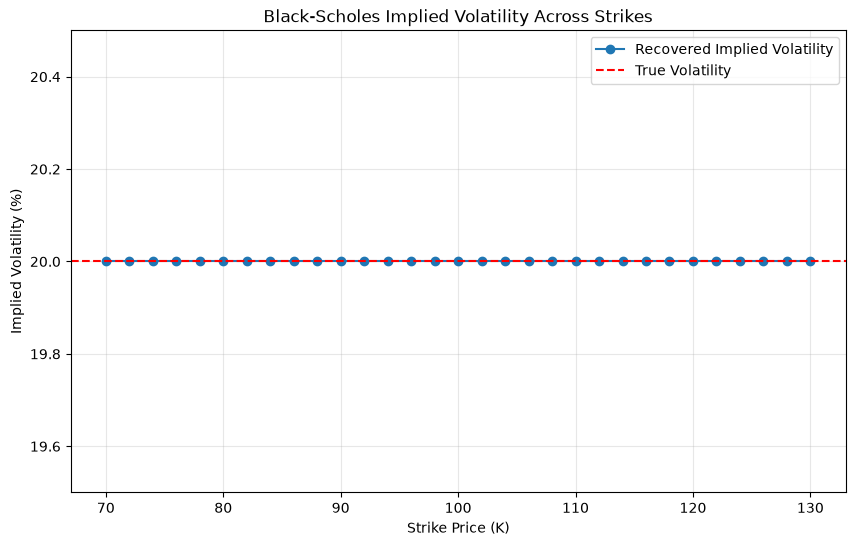

In [9]:
# Strike prices
K_values = np.linspace(70, 130, 31)

# Constant Black-Scholes volatility
sigma_flat = 0.20

# Store synthetic prices and implied volatilities
option_prices = []
implied_volatilities = []

for K_i in K_values:

    # Generate synthetic call price
    price = black_scholes(
        S, K_i, T, r, sigma_flat, "call")

    option_prices.append(price)

    # Recover implied volatility using Brent
    implied_sigma = iv.implied_volatility_brent(
        price, S, K_i, T, r, "call")

    implied_volatilities.append(implied_sigma)

# Convert lists to NumPy arrays
option_prices = np.array(option_prices)
implied_volatilities = np.array(implied_volatilities)

# Maximum volatility recovery error
max_error = np.max(
    np.abs(implied_volatilities - sigma_flat))

print(f"Number of strikes: {len(K_values)}")
print(f"Target Volatility: {sigma_flat:.6%}")
print(f"Maximum IV Recovery Error: {max_error:.2e}")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    K_values,
    implied_volatilities * 100,
    marker="o",
    label="Recovered Implied Volatility")

plt.axhline(
    sigma_flat * 100,
    color="red",
    linestyle="--",
    label="True Volatility")

plt.xlabel("Strike Price (K)")
plt.ylabel("Implied Volatility (%)")
plt.title("Black-Scholes Implied Volatility Across Strikes")

plt.legend()
plt.grid(True, alpha=0.3)
# Display economically meaningful volatility differences
plt.ylim(19.5, 20.5)
# Disable scientific offset on the y-axis
plt.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.show()

Maximum Smile Recovery Error: 2.12e-13


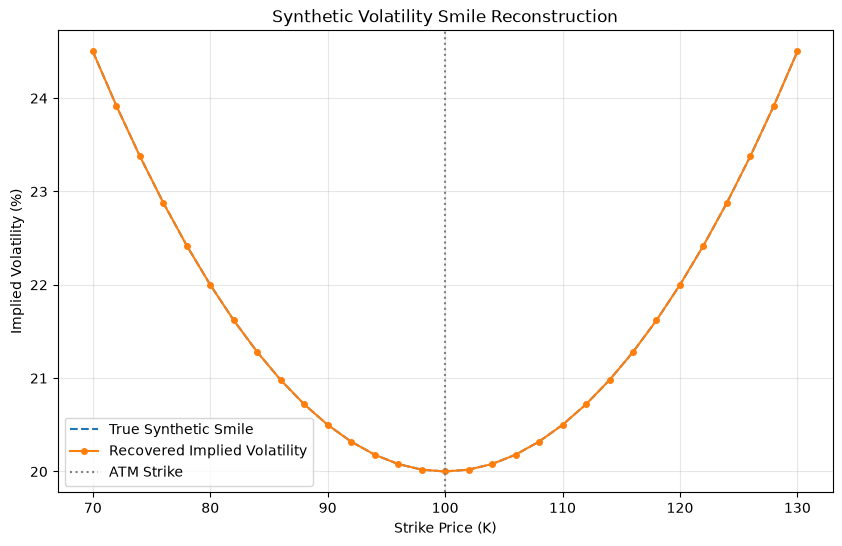

In [10]:
# Define synthetic volatility smile
sigma_smile = 0.20 + 0.50 * (K_values / S - 1)**2

# Generate synthetic option prices
smile_prices = []

for K_i, sigma_i in zip(K_values, sigma_smile):

    price = black_scholes(
        S, K_i, T, r, sigma_i, "call")

    smile_prices.append(price)

smile_prices = np.array(smile_prices)

# Recover implied volatilities using Brent
recovered_smile = []

for K_i, price in zip(K_values, smile_prices):

    implied_sigma = iv.implied_volatility_brent(
        price, S, K_i, T, r, "call")

    recovered_smile.append(implied_sigma)

recovered_smile = np.array(recovered_smile)

# Calculate recovery error
max_error = np.max(np.abs(recovered_smile - sigma_smile))

print(f"Maximum Smile Recovery Error: {max_error:.2e}")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    K_values,
    sigma_smile * 100,
    linestyle="--",
    label="True Synthetic Smile")

plt.plot(
    K_values,
    recovered_smile * 100,
    marker="o",
    markersize=4,
    label="Recovered Implied Volatility")

plt.axvline(S, color="gray", linestyle=":", label="ATM Strike")

plt.xlabel("Strike Price (K)")
plt.ylabel("Implied Volatility (%)")
plt.title("Synthetic Volatility Smile Reconstruction")

plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(
    figures_path / "synthetic_volatility_smile.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

In [11]:
# No-arbitrage checks for synthetic call prices

# First differences across strikes
first_diff = np.diff(smile_prices)

# Second differences across equally spaced strikes
second_diff = np.diff(smile_prices, n=2)

# Check monotonicity
is_decreasing = np.all(first_diff <= 0)

# Check convexity
is_convex = np.all(second_diff >= 0)

# Additional check: call-spread slope bounds
strike_steps = np.diff(K_values)
slopes = first_diff / strike_steps

slope_bounds_valid = np.all(
    (slopes >= -np.exp(-r * T)) & (slopes <= 0))

print(f"Call prices decreasing: {is_decreasing}")
print(f"Call prices convex: {is_convex}")
print(f"Call spread bounds satisfied: {slope_bounds_valid}")

print(f"\nMaximum first difference: {np.max(first_diff):.6f}")
print(f"Minimum second difference: {np.min(second_diff):.6f}")

Call prices decreasing: True
Call prices convex: True
Call spread bounds satisfied: True

Maximum first difference: -0.139679
Minimum second difference: 0.016342


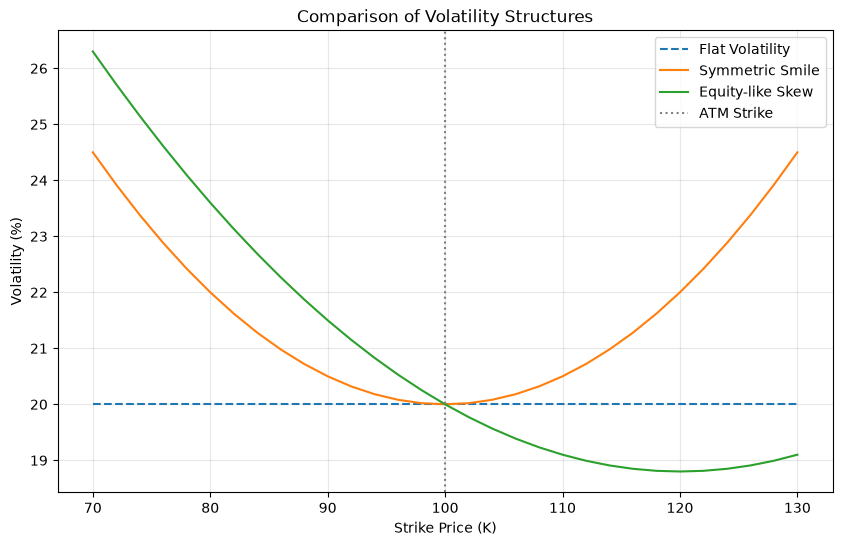

In [12]:
# Synthetic equity-like volatility skew
moneyness = K_values / S

sigma_skew = (
    0.20
    - 0.12 * (moneyness - 1)
    + 0.30 * (moneyness - 1)**2)

# Plot the three volatility structures
plt.figure(figsize=(10, 6))

plt.plot(
    K_values,
    np.full_like(K_values, 20.0),
    linestyle="--",
    label="Flat Volatility")

plt.plot(
    K_values,
    sigma_smile * 100,
    label="Symmetric Smile")

plt.plot(
    K_values,
    sigma_skew * 100,
    label="Equity-like Skew")

plt.axvline(
    S, color="gray", linestyle=":",
    label="ATM Strike")

plt.xlabel("Strike Price (K)")
plt.ylabel("Volatility (%)")
plt.title("Comparison of Volatility Structures")

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    figures_path / "volatility_structures_comparison.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

In [13]:
# Generate synthetic call prices using the equity-like skew
skew_prices = []

for K_i, sigma_i in zip(K_values, sigma_skew):

    price = black_scholes(
        S, K_i, T, r, sigma_i, "call"
    )

    skew_prices.append(price)

skew_prices = np.array(skew_prices)

# First and second differences
first_diff_skew = np.diff(skew_prices)
second_diff_skew = np.diff(skew_prices, n=2)

# Monotonicity
is_decreasing_skew = np.all(first_diff_skew <= 0)

# Convexity
is_convex_skew = np.all(second_diff_skew >= 0)

# Call spread bounds
slopes_skew = first_diff_skew / np.diff(K_values)

slope_bounds_skew = np.all(
    (slopes_skew >= -np.exp(-r * T)) &
    (slopes_skew <= 0)
)

# Results
print(f"Call prices decreasing: {is_decreasing_skew}")
print(f"Call prices convex: {is_convex_skew}")
print(f"Call spread bounds satisfied: {slope_bounds_skew}")

print(f"\nMaximum first difference: {np.max(first_diff_skew):.6f}")
print(f"Minimum second difference: {np.min(second_diff_skew):.6f}")

Call prices decreasing: True
Call prices convex: True
Call spread bounds satisfied: True

Maximum first difference: -0.203780
Minimum second difference: 0.016942


Maximum Skew Recovery Error: 8.07e-14
Mean Skew Recovery Error: 8.47e-15


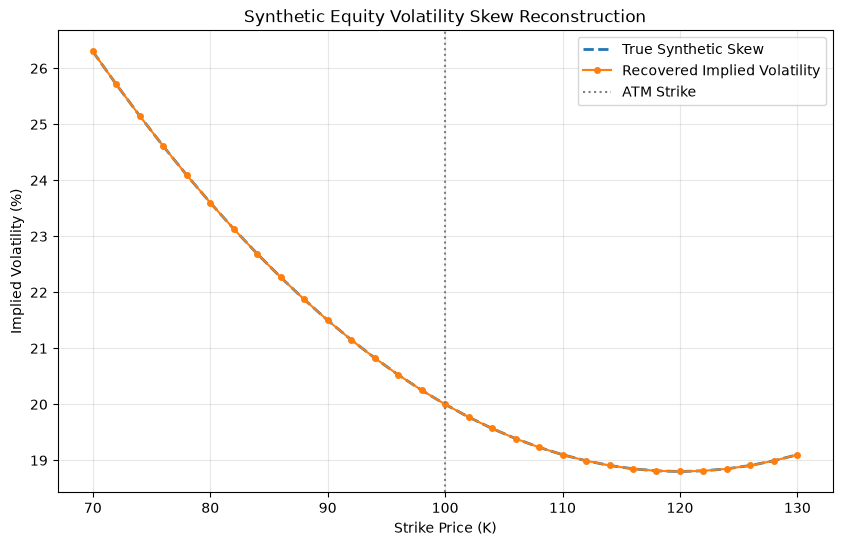

In [14]:
# Recover implied volatilities from skew-based option prices
recovered_skew = []

for K_i, price in zip(K_values, skew_prices):

    implied_sigma = iv.implied_volatility_brent(
        price, S, K_i, T, r, "call"
    )

    recovered_skew.append(implied_sigma)

recovered_skew = np.array(recovered_skew)

# Calculate recovery error
skew_recovery_error = np.abs(recovered_skew - sigma_skew)

print(f"Maximum Skew Recovery Error: {np.max(skew_recovery_error):.2e}")
print(f"Mean Skew Recovery Error: {np.mean(skew_recovery_error):.2e}")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    K_values,
    sigma_skew * 100,
    linestyle="--",
    linewidth=2,
    label="True Synthetic Skew"
)

plt.plot(
    K_values,
    recovered_skew * 100,
    marker="o",
    markersize=4,
    label="Recovered Implied Volatility"
)

plt.axvline(
    S,
    color="gray",
    linestyle=":",
    label="ATM Strike"
)

plt.xlabel("Strike Price (K)")
plt.ylabel("Implied Volatility (%)")
plt.title("Synthetic Equity Volatility Skew Reconstruction")

plt.legend()
plt.grid(True, alpha=0.3)
# Save figure
plt.savefig(
    figures_path / "synthetic_equity_skew.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()